<a href="https://colab.research.google.com/github/PunamBhatia/LogicMojo-AI-ML-April26-Punam/blob/main/LoRA_SFT/LoRA_Qwen2_5_0_5BEmotionDataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install -U "transformers==5.17.0" "datasets==5.0.1" "trl==0.28.0" "peft==0.21.0" accelerate scikit-learn


In [ ]:
import json, random, importlib.metadata as metadata
from pathlib import Path
import numpy as np
import torch
from datasets import load_dataset, Dataset
from transformers import AutoModelForCausalLM , AutoTokenizer
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

SEED=42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print('GPU:', torch.cuda.get_device_name(0))
for package in ('torch', 'transformers', 'datasets', 'trl', 'peft'):
    print(package, metadata.version(package))
import trl

GPU: Tesla T4
torch 2.11.0+cu130
transformers 5.17.0
datasets 5.0.1
trl 0.28.0
peft 0.21.0


In [ ]:
DATASET_ID, DATASET_CONFIG='dair-ai/emotion','split'

raw= load_dataset(DATASET_ID,DATASET_CONFIG)
LABELS= list(raw["train"].features["label"].names)

print(LABELS)

TRAIN_ROWS, VAL_ROWS=1200,240

train_raw= raw["train"].shuffle(True).select(range(TRAIN_ROWS))
val_raw=raw["validation"].shuffle(True).select(range(VAL_ROWS))

print({part: len(raw[part]) for part in ['train','validation','test']})

#print sample 3 inputs

for sample in raw['train'].select(range(3)):
    print({"Text": sample['text'],"Label": LABELS[sample['label']]})




README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
{'train': 16000, 'validation': 2000, 'test': 2000}
{'Text': 'i didnt feel humiliated', 'Label': 'sadness'}
{'Text': 'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake', 'Label': 'sadness'}
{'Text': 'im grabbing a minute to post i feel greedy wrong', 'Label': 'anger'}


In [ ]:
#lets check count for each category of emotions
from collections import Counter


for name,part in [('train', train_raw),('validation',val_raw)]:
  counts= Counter(part["label"])
  print(name,{label:counts[i] for i,label in enumerate(LABELS) })


train {'sadness': 347, 'joy': 398, 'love': 100, 'anger': 167, 'fear': 147, 'surprise': 41}
validation {'sadness': 66, 'joy': 84, 'love': 16, 'anger': 40, 'fear': 26, 'surprise': 8}


In [ ]:
#lets load the model
MODEL_ID='Qwen/Qwen2.5-0.5B-Instruct'
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID)

if tokenizer.pad_token is None:
  tokenizer.pad_token=tokenizer.eos_token

SYSTEM_INSTRUCTION=(
    'Classify the emotions expressed in the text.'
    'Choose exactly one label:'+','.join(LABELS)+'. '
    'Return only the label with no explaination.'
)

#openai format
def prompt_for(text):
  messages=[{'role':'system','content':SYSTEM_INSTRUCTION },
            {'role':'user', 'content':'Text: '+text}]
  #print(messages)
  return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

print('eos token:',repr(tokenizer.eos_token), 'pad token', repr(tokenizer.pad_token))

print(prompt_for(train_raw[0]['text'])[-500:])



eos token: '<|im_end|>' pad token '<|endoftext|>'
<|im_start|>system
Classify the emotions expressed in the text.Choose exactly one label:sadness,joy,love,anger,fear,surprise. Return only the label with no explaination.<|im_end|>
<|im_start|>user
Text: ive been feeling a little bit anxious of late as far as my relations or lack thereof with some of the ward and some of the investigators go so im excited to be able to ponder that in the temple and see if i can come up with a plan with the lords help<|im_end|>
<|im_start|>assistant



In [ ]:
MAX_LEN=256

def to_sft(part):
  records={'prompt':[],'completion':[]}
  dropped=0
  for row in part:
    prompt=prompt_for(row['text'])
    completion=LABELS[row['label']]+tokenizer.eos_token
    length=len(tokenizer(prompt+completion, add_special_token=False)['input_ids'])
    if(length>MAX_LEN):
      dropped+=1
      continue
    records['prompt'].append(prompt)
    records['completion'].append(completion)
  print('dropped',dropped)
  return Dataset.from_dict(records), dropped

In [ ]:
train_sft, train_dropped= to_sft(train_raw)
val_sft, val_dropped=to_sft(val_raw)
print('train/val kept records',len(train_sft),len(val_sft))
print('long rows excluded',train_dropped,val_dropped)
print('prompt ending: ',train_sft[0]['prompt'][-100:])
print('completion ending',train_sft[0]['completion'][-100:])

dropped 0
dropped 0
train/val kept records 1200 240
long rows excluded 0 0
prompt ending:  the temple and see if i can come up with a plan with the lords help<|im_end|>
<|im_start|>assistant

completion ending fear<|im_end|>


In [ ]:
#lets exclude the prompt from loss calculation so replace prompt tokens with -100 token id
example=train_sft[0]
prompt_tokenId_to_replace=tokenizer(example["prompt"], add_special_tokens=False)["input_ids"]
full_input_token_ids= tokenizer(example["prompt"]+example["completion"], add_special_tokens=False)['input_ids']

assert full_input_token_ids[:len(prompt_tokenId_to_replace)]==prompt_tokenId_to_replace
loss_labels=[-100]*len(prompt_tokenId_to_replace)+full_input_token_ids[len(prompt_tokenId_to_replace):]
print(loss_labels[:100])


[-100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100]


In [ ]:
IS_BF_SUPPORTED= bool(torch.cuda.is_bf16_supported())
DTYPE= torch.bfloat16 if IS_BF_SUPPORTED else torch.float16

model=AutoModelForCausalLM.from_pretrained(MODEL_ID, device_map='auto', torch_dtype=DTYPE)
model.to('cuda')
model.eval()
print('dtype:',DTYPE, 'parameters:', f'{sum(p.numel() for p in model.parameters()),}')

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

dtype: torch.bfloat16 parameters: (494032768,)


In [ ]:
from collections import Counter
from torch import nn

print(' architecture: ', model.config.model_type )
print(' total decoder blocks', len(model.model.layers))

linear_modules=[(name, module) for name, module in model.named_modules() if isinstance(module,nn.Linear) ]

print('Linear module types and counts: ', Counter([name.rsplit('.',1)[-1] for name,_ in linear_modules]))

first_block=[(name, tuple(module.weight.shape)) for name, module in linear_modules if '.layers.0.' in name]

for name,shape in first_block:
  print(name,shape)

 architecture:  qwen2
 total decoder blocks 24
Linear module types and counts:  Counter({'q_proj': 24, 'k_proj': 24, 'v_proj': 24, 'o_proj': 24, 'gate_proj': 24, 'up_proj': 24, 'down_proj': 24, 'lm_head': 1})
model.layers.0.self_attn.q_proj (896, 896)
model.layers.0.self_attn.k_proj (128, 896)
model.layers.0.self_attn.v_proj (128, 896)
model.layers.0.self_attn.o_proj (896, 896)
model.layers.0.mlp.gate_proj (4864, 896)
model.layers.0.mlp.up_proj (4864, 896)
model.layers.0.mlp.down_proj (896, 4864)


In [ ]:
attention_qv={"q_proj","v_proj"}
attention_all= {"q_proj","k_proj","v_proj","o_proj"}
attention_mlp= attention_all | {"gate_proj","up_proj","down_proj"}

def adapter_matrix_count(target_names,rank=8):
  chosen=[(name,module) for name,module in linear_modules if name.rsplit('.',1)[-1] in target_names]
  values= sum(rank* (module.in_features+module.out_features) for _, module in chosen)
  return len(chosen), values

for title, target in [("Q and V",attention_qv),("all attention",attention_all),("attention+ MLP", attention_mlp)]:
  module_count, values= adapter_matrix_count(target)
  print(f"title: {title}, modules: {module_count},  rank =8 values={values}")

title: Q and V, modules: 48,  rank =8 values=540672
title: all attention, modules: 96,  rank =8 values=1081344
title: attention+ MLP, modules: 168,  rank =8 values=4399104


In [ ]:
#lets use sample 15 rows from validation data to check if base model performance good

def generate(active_model, text):
  encoded= tokenizer(prompt_for(text), return_tensors='pt').to('cuda')
  #print("encoded:", encoded)
  with torch.inference_mode():
    output= active_model.generate(**encoded, max_new_tokens=8, do_sample=False, pad_token_id=tokenizer.pad_token_id)
    new_tokens=output[0, encoded['input_ids'].shape[1]:]
  return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

val_preview_rows= raw["validation"].shuffle(seed=SEED).select(range(15))
base_model_predictions= [generate(model,row["text"]) for row in val_preview_rows]
#print(base_model_predictions)
for row, answer in zip(val_preview_rows,base_model_predictions):
  print({'text':row['text'],'label':LABELS[row['label']],'prediction':answer})

{'text': 'i usually increase the font and maybe if i am feeling brave change to a non standard font style', 'label': 'joy', 'prediction': 'anger'}
{'text': 'i want to feel pretty or handsome or something', 'label': 'joy', 'prediction': 'love'}
{'text': 'i slipped out feeling a bit shaken', 'label': 'fear', 'prediction': 'shaken'}
{'text': 'i am left feeling dazed and confused', 'label': 'surprise', 'prediction': 'sadness'}
{'text': 'i feel alarmed her fingers gripping tight i see her pleading eyes so i start to disguise and say that everythings alright', 'label': 'fear', 'prediction': 'sadness'}
{'text': 'i was looking at her and leaning a bit forward feeling really keen on to her', 'label': 'joy', 'prediction': 'love'}
{'text': 'i feel a little bit more nostalgic when those memories come to mind', 'label': 'love', 'prediction': 'love'}
{'text': 'i am feeling so invigorated and so ready to keep pushing on to goal', 'label': 'joy', 'prediction': 'joy'}
{'text': 'i have a well staffed of

In [ ]:
#lets add adapter configurations
lora_config=LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=attention_qv,
    lora_dropout=0.05,
    bias='none',
    task_type='CAUSAL_LM'
)

In [ ]:
%pip -q  uninstall -y torchao

In [ ]:
#lets add trl- gives model training hyperparameters i.e. exact fine tunning configuration
training_args = SFTConfig(
    output_dir="/content/emotion_lora_training_withqwen",
    max_length=MAX_LEN,            # sequences longer than this were already dropped
    completion_only_loss=True,        # grade the label; keep the prompt as context
    packing=False,                    # one post per sequence, so the mask stays easy to inspect
    per_device_train_batch_size=2,    # small, so activations fit
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=8,    # one optimizer step sees 2 * 8 = 16 posts
    max_steps=60,                     # a class clock, not an epoch and not a quality target
    learning_rate=2e-4,               # step size for the adapter weights
    warmup_steps=3,                   # ramp that step size over the first 3 of 60 updates
    eval_strategy="steps",
    eval_steps=20,                    # validation loss at steps 20, 40, and 60
    logging_steps=10,
    save_strategy="no",               # the Drive cell is the save that matters
    fp16=not IS_BF_SUPPORTED,
    bf16=IS_BF_SUPPORTED,                    # match the dtype the GPU actually supports
    gradient_checkpointing=True,      # recompute some activations to save memory
    optim="adamw_torch",
    seed=SEED,
    report_to="none",
    eos_token=tokenizer.eos_token,
    pad_token=tokenizer.pad_token,
)
trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_sft,
    eval_dataset=val_sft,
    peft_config=lora_config,          # the plan from the board; the trainer inserts the matrices
    processing_class=tokenizer,
)
trainer.model.print_trainable_parameters()



Adding EOS to train dataset:   0%|          | 0/1200 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/1200 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/1200 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/240 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/240 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/240 [00:00<?, ? examples/s]

trainable params: 540,672 || all params: 494,573,440 || trainable%: 0.1093


In [ ]:
train_result = trainer.train()
print('final training metrics:', train_result.metrics)
for log in trainer.state.log_history:
    if 'loss' in log or 'eval_loss' in log:
        print({key: log[key] for key in ('step','loss','eval_loss') if key in log})

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Step,Training Loss,Validation Loss
20,0.518982,0.506602
40,0.445445,0.470261
60,0.445941,0.444152


final training metrics: {'train_runtime': 207.0885, 'train_samples_per_second': 4.636, 'train_steps_per_second': 0.29, 'total_flos': 166015940952576.0, 'train_loss': 0.5511080185572307}
{'step': 10, 'loss': 0.943278694152832}
{'step': 20, 'loss': 0.5189816951751709}
{'step': 20, 'eval_loss': 0.5066016316413879}
{'step': 30, 'loss': 0.5381876945495605}
{'step': 40, 'loss': 0.445444917678833}
{'step': 40, 'eval_loss': 0.47026124596595764}
{'step': 50, 'loss': 0.4148142337799072}
{'step': 60, 'loss': 0.4459408760070801}
{'step': 60, 'eval_loss': 0.44415220618247986}


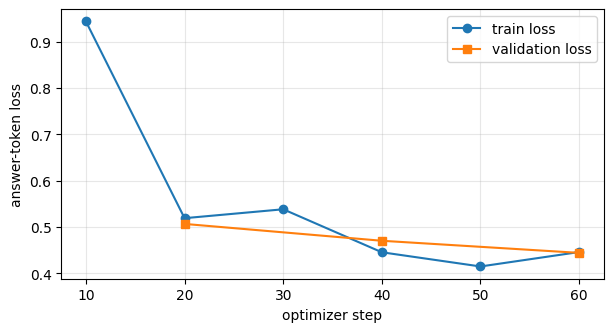

In [ ]:
import matplotlib.pyplot as plt
train_points = [(x['step'],x['loss']) for x in trainer.state.log_history if 'loss' in x]
val_points = [(x['step'],x['eval_loss']) for x in trainer.state.log_history if 'eval_loss' in x]
plt.figure(figsize=(7,3.5))
if train_points: plt.plot(*zip(*train_points), marker='o', label='train loss')
if val_points: plt.plot(*zip(*val_points), marker='s', label='validation loss')
plt.xlabel('optimizer step'); plt.ylabel('answer-token loss'); plt.grid(alpha=.3); plt.legend(); plt.show()

In [ ]:
trainer.model.eval()
adapted_preview = [generate(trainer.model, row['text']) for row in val_preview_rows]
for row, before, after in zip(val_preview_rows, base_model_predictions, adapted_preview):
    print({'gold':LABELS[row['label']], 'base':before, 'adapter':after, 'text':row['text'][:80]})


{'gold': 'joy', 'base': 'anger', 'adapter': 'joy', 'text': 'i usually increase the font and maybe if i am feeling brave change to a non stan'}
{'gold': 'joy', 'base': 'love', 'adapter': 'joy', 'text': 'i want to feel pretty or handsome or something'}
{'gold': 'fear', 'base': 'shaken', 'adapter': 'fear', 'text': 'i slipped out feeling a bit shaken'}
{'gold': 'surprise', 'base': 'sadness', 'adapter': 'sadness', 'text': 'i am left feeling dazed and confused'}
{'gold': 'fear', 'base': 'sadness', 'adapter': 'sadness', 'text': 'i feel alarmed her fingers gripping tight i see her pleading eyes so i start to '}
{'gold': 'joy', 'base': 'love', 'adapter': 'joy', 'text': 'i was looking at her and leaning a bit forward feeling really keen on to her'}
{'gold': 'love', 'base': 'love', 'adapter': 'sadness', 'text': 'i feel a little bit more nostalgic when those memories come to mind'}
{'gold': 'joy', 'base': 'joy', 'adapter': 'joy', 'text': 'i am feeling so invigorated and so ready to keep pushing on

In [ ]:
#lets save fine tunned model
from google.colab import drive
drive.mount('/content/drive')
ARTIFACT_DIR = Path('/content/emotion_lora_training_withqwen/decoder_lora_emotion')
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
print(ARTIFACT_DIR)

Mounted at /content/drive
/content/emotion_lora_training_withqwen/decoder_lora_emotion


In [ ]:
# Save LoRA adapter, tokenizer, and experiment settings.

trainer.model.save_pretrained(ARTIFACT_DIR, safe_serialization=True)
tokenizer.save_pretrained(ARTIFACT_DIR)
manifest = {
    'model_id': MODEL_ID, 'dataset_id': DATASET_ID, 'dataset_config': DATASET_CONFIG,
    'labels': LABELS, 'system_instruction': SYSTEM_INSTRUCTION,
    'seed': SEED, 'train_rows_requested': TRAIN_ROWS, 'val_rows_requested': VAL_ROWS,
    'train_rows_kept': len(train_sft), 'val_rows_kept': len(val_sft),
    'max_length': MAX_LEN, 'max_steps': training_args.max_steps,
    'lora_r': lora_config.r, 'lora_alpha': lora_config.lora_alpha,
    'target_modules': list(lora_config.target_modules),
    'package_versions': {p: metadata.version(p) for p in ('torch','transformers','datasets','trl','peft')},
}

In [ ]:
# List saved artifact sizes after the Drive save.

for item in sorted(ARTIFACT_DIR.iterdir()):
    if item.is_file():
        print(f'{item.name:35} {item.stat().st_size/1024**2:8.3f} MiB')

README.md                              0.005 MiB
adapter_config.json                    0.001 MiB
adapter_model.safetensors              2.074 MiB
chat_template.jinja                    0.002 MiB
tokenizer.json                        10.893 MiB
tokenizer_config.json                  0.001 MiB
